# **Section 10: Nested Cross-Validation and Final Model Validation**

This notebook implements **nested cross-validation** to estimate the performance of the best 3 models, as for the CNVs and the SVs.

**Nested CV Structure:**
- **Outer loop (10 folds):** Estimates true model performance. Each outer test fold contains whole Sequence Types (STs), so that the model is always tested on lineages it was not trained on.
- **Inner loop (5-fold):** Hyperparameter tuning via GridSearchCV

**Models evaluated:**
1. Logistic Regression
2. XGBoost
3. K-Nearest Neighbours

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
sns.set_palette("pastel")

## **1. Load Data**

In [2]:
# Load the features as they are before the feature selection of notebook 03,
# which is redone inside each fold below
snp_train = pd.read_csv("Data/snp_train.csv", index_col=0)
snp_test = pd.read_csv("Data/snp_test.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test.csv", index_col=0)

snp_all = pd.concat([snp_train, snp_test], axis=0)
profiles = pd.concat([profiles_train, profiles_test], axis=0)


In [3]:
X = snp_all.values
y = profiles.loc[snp_all.index].values.ravel()

print(f"Data set shape: {X.shape}")
print(f"Categories: {np.unique(y)}")

Data set shape: (226, 78850)
Categories: [0 1]


In [4]:
# load metadata
metadata = pd.read_csv("../genome_metadata_cleaned.csv", index_col=0, dtype={'ST': str})
metadata['ST'] = metadata['ST'].fillna('unknown')
print(f"Metadata shape: {metadata.shape}")
print(f"Metadata columns: {metadata.columns}")

Metadata shape: (227, 7)
Metadata columns: Index(['genome_name', 'source', 'species', 'ST', 'location',
       'resistance_profile', 'status'],
      dtype='str')


In [5]:
# Keep the samples of the data set, in the same order as the rows of X and y
metadata = metadata.loc[snp_all.index, :]
print(f"There are {metadata['ST'].nunique()} different STs in the data")

There are 59 different STs in the data


## **2. Nested Cross-Validation**

### **2.1 Test set definition**
Let's define 10 different test sets each containing separate STs. Samples without a known ST are grouped together as "unknown".

Let's first create a data frame that contains the number of samples per ST.

In [6]:
ST_df = pd.DataFrame({
    'ST': metadata["ST"].value_counts().index,
    'count': metadata["ST"].value_counts().values
})

# Sort largest counts first
ST_df = ST_df.sort_values('count', ascending=False)

We will now create test sets based on the ST, making sure that each test set has approximately the same number of samples: each ST, from largest to smallest, is assigned to the test set that currently has the fewest samples.

In [7]:
n_splits = 10

# Number of samples in each split (is updated as samples are assigned to a split)
split_counts = [0] * n_splits

# Assigned split for each ST
split_assignment = []

for _, sample in ST_df.iterrows():

    # Find the split with the smallest total and return its index
    split = split_counts.index(min(split_counts))

    # assign that split to the current ST
    split_assignment.append(split)

    # adjust the number of samples in that split
    split_counts[split] += sample['count']

ST_df['split'] = split_assignment

print(ST_df.head(15))
print(split_counts)

          ST  count  split
0         70     23      0
1   Novel ST     20      1
2        512     15      2
3        306     14      3
4         10     13      4
5    unknown     10      5
6         54      8      6
7        167      7      7
8         34      7      8
9        219      6      9
10        93      5      9
11        33      5      7
12       654      5      8
13        46      5      6
14       206      4      5
[23, 23, 23, 23, 23, 23, 22, 22, 22, 22]


We now need to assign a split to each sample in the metadata. Let's map the ST to a test split according to the information in ST_df

In [8]:
ST_lookup = ST_df.set_index("ST")["split"]
metadata["split"] = metadata["ST"].map(ST_lookup)

# Number of resistant and susceptible samples in each outer test fold
print(pd.crosstab(metadata["split"], y, rownames=['fold'], colnames=['SXT']))

SXT    0   1
fold        
0     12  11
1      8  15
2     13  10
3     11  12
4     10  13
5      9  14
6     11  11
7     11  11
8     13   9
9      5  17


### **2.2 Feature selection inside each fold**

The feature selection of notebook 03 was done once, on the whole training set. Notebook 10
then evaluated those features on folds that include the samples the selection was based on,
so the resulting scores were optimistic: features chosen partly because they separate
resistant from susceptible samples in a lineage are then tested on that same lineage.

The class below redoes the selection of notebook 03 from scratch, and the nested CV function
fits it on the training samples of each outer fold only. The outer test fold therefore takes
no part in choosing its own features, and the reported accuracy and AUC are honest estimates
for lineages the whole procedure has never seen. The number of features kept now varies from
fold to fold, so it is printed for each one.

The selection is fitted once per outer fold rather than inside the inner loop, which keeps
the outer estimate unbiased (the test fold is never used) while staying fast.

In [9]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import chi2
from scipy.stats import false_discovery_control


class FoldFeatureSelector(BaseEstimator, TransformerMixin):
    """Notebook 03's feature selection, refitted from scratch on the training part of one fold.

    1. Drop features with a low variance: for a binary feature the variance is p(1-p).
    2. Keep the features significantly associated with resistance (chi2 score,
       Benjamini-Hochberg adjusted p-value < alpha). If fewer than min_features are
       significant, fall back to the top fallback_k features by chi2 score.
    3. Collapse features that have exactly the same presence/absence pattern into one.
    """

    def __init__(self, var_threshold=0.015, alpha=0.05, min_features=5, fallback_k=20):
        self.var_threshold = var_threshold
        self.alpha = alpha
        self.min_features = min_features
        self.fallback_k = fallback_k

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()

        # 1. Variance filter
        p = X.mean(axis=0)
        kept = np.flatnonzero(p * (1 - p) >= self.var_threshold)
        if kept.size == 0:
            self.support_ = kept
            return self

        # 2. Association with resistance
        scores, p_values = chi2(X[:, kept], y)
        p_adj = false_discovery_control(np.nan_to_num(p_values, nan=1.0), method='bh')
        significant = np.flatnonzero(p_adj < self.alpha)
        if significant.size < self.min_features:
            ranked = np.argsort(-np.nan_to_num(scores, nan=-np.inf))
            significant = ranked[:self.fallback_k]
        selected = kept[np.sort(significant)]

        # 3. One feature per unique presence/absence pattern
        _, first = np.unique(X[:, selected], axis=1, return_index=True)
        self.support_ = np.sort(selected[first])
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.support_]


### **2.2 Nested CV Function**
Now that we have assigned an outer fold number to each sample, we can define a function that performs nested cross-validation. If an outer test fold contains only resistant or only susceptible samples, the AUC (and the ROC curve) cannot be computed for that fold; it is then skipped for the AUC and reported as NaN.

In [10]:
def nested_cross_validation(model_name, pipeline, param_grid, X, y, cv_inner=5):
    """
    Perform nested cross-validation for model evaluation.
    Returns a dictionary with nested CV results
    """
    outer_folds = sorted(metadata["split"].unique())

    outer_accuracies = []
    outer_aucs = []
    best_params_list = []
    n_features_per_fold = []

    # Store predictions during each fold
    fold_predictions = []

    # Store ROC curve for each fold. We need to interpolate them onto a common FPR grid so we can compare them
    common_grid = np.linspace(0, 1, 100)
    fold_tprs = []

    for fold in outer_folds:

        #split the sets
        train_idx = (metadata["split"] != fold).values
        test_idx = (metadata["split"] == fold).values

        X_train, y_train = X[train_idx], y[train_idx]
        X_test, y_test = X[test_idx], y[test_idx]

        # Feature selection, refitted on this fold's training samples only
        selector = FoldFeatureSelector().fit(X_train, y_train)
        X_train, X_test = selector.transform(X_train), selector.transform(X_test)
        n_features_per_fold.append(X_train.shape[1])

        # perform cross validation
        grid_search = GridSearchCV(
            pipeline,
            param_grid,
            cv=StratifiedKFold(n_splits=cv_inner, shuffle=True, random_state=2),
            scoring='accuracy',
            n_jobs=-1,
            verbose=0
        )

        # fit model and get predictions & metrics
        grid_search.fit(X_train, y_train)

        y_pred = grid_search.predict(X_test)
        y_proba = grid_search.predict_proba(X_test)[:, 1]

        accuracy = accuracy_score(y_test, y_pred)

        # store metrics
        outer_accuracies.append(accuracy)
        best_params_list.append(grid_search.best_params_)

        # Store the predictions
        fold_predictions.append(pd.DataFrame({
            'sample_id': snp_all.index[test_idx],
            'fold': fold,
            'y_true': y_test,
            'y_pred': y_pred,
            'y_proba': y_proba
        }))

        # AUC and ROC curve (only defined if the fold contains both classes)
        if len(np.unique(y_test)) == 2:
            auc = roc_auc_score(y_test, y_proba)
            fpr, tpr, _ = roc_curve(y_test, y_proba)
            interp_tpr = np.interp(common_grid, fpr, tpr)
            interp_tpr[0] = 0.0
            fold_tprs.append(interp_tpr)
        else:
            auc = np.nan
        outer_aucs.append(auc)

        # monitor progress
        print(f'{model_name}, Fold {fold}: {X_train.shape[1]} features, Accuracy={accuracy:.4f}, AUC={auc:.4f}')

    n_folds = len(outer_folds)
    n_auc_folds = int(np.sum(~np.isnan(outer_aucs)))
    mean_tpr = np.mean(fold_tprs, axis=0)
    mean_tpr[-1] = 1.0
    std_tpr = np.std(fold_tprs, axis=0)

    results = {
        'model_name': model_name,
        'accuracies': np.array(outer_accuracies),
        'aucs': np.array(outer_aucs),
        'accuracy_mean': np.mean(outer_accuracies),
        'accuracy_std': np.std(outer_accuracies),
        'accuracy_ci': 1.96 * np.std(outer_accuracies) / np.sqrt(n_folds),
        'auc_mean': np.nanmean(outer_aucs),
        'auc_std': np.nanstd(outer_aucs),
        'auc_ci': 1.96 * np.nanstd(outer_aucs) / np.sqrt(n_auc_folds),
        'best_params_list': best_params_list,
        'n_features_per_fold': n_features_per_fold,
        'mean_fpr': common_grid,
        'mean_tpr': mean_tpr,
        'std_tpr': std_tpr,
        'predictions': pd.concat(fold_predictions, ignore_index=True)
    }
    return results

### **2.3 Define Models and Hyperparameter Grids**

In [11]:
# Logistic Regression
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        l1_ratio=0.5,
        C=1.0,
        max_iter=1000,
        random_state=4,
    )),
])

lr_param_grid = {
    "logreg__C": np.logspace(-2, 2, 5),
    "logreg__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]
}

# XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    random_state=1,
    eval_metric='logloss'
)

xgb_param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'reg_alpha': [0.0, 0.1],  # L1 regularization
    'reg_lambda': [0.1, 1.0]  # L2 regularization
}

# KNN
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

knn_param_grid = {
    'knn__n_neighbors': [5, 10, 15, 20, 30, 35, 40]
}

### **2.4 Run Nested Cross-Validation**

In [12]:
results_lr = nested_cross_validation(
    'Logistic Regression',
    lr_pipeline,
    lr_param_grid,
    X, y
)
print()

Logistic Regression, Fold 0: 19 features, Accuracy=0.4783, AUC=0.5114


Logistic Regression, Fold 1: 20 features, Accuracy=0.4348, AUC=0.4833


Logistic Regression, Fold 2: 20 features, Accuracy=0.6957, AUC=0.6769


Logistic Regression, Fold 3: 20 features, Accuracy=0.5217, AUC=0.6136


Logistic Regression, Fold 4: 19 features, Accuracy=0.3043, AUC=0.3538


Logistic Regression, Fold 5: 20 features, Accuracy=0.6087, AUC=0.6627


Logistic Regression, Fold 6: 923 features, Accuracy=0.5909, AUC=0.6033


Logistic Regression, Fold 7: 19 features, Accuracy=0.6364, AUC=0.8017


Logistic Regression, Fold 8: 20 features, Accuracy=0.6818, AUC=0.6880


Logistic Regression, Fold 9: 20 features, Accuracy=0.6818, AUC=0.5118



In [13]:
results_xgb = nested_cross_validation(
    'XGB',
    xgb_model,
    xgb_param_grid,
    X, y
)
print()

XGB, Fold 0: 19 features, Accuracy=0.4348, AUC=0.5265


XGB, Fold 1: 20 features, Accuracy=0.4783, AUC=0.4667


XGB, Fold 2: 20 features, Accuracy=0.6957, AUC=0.7692


XGB, Fold 3: 20 features, Accuracy=0.5652, AUC=0.5985


XGB, Fold 4: 19 features, Accuracy=0.3913, AUC=0.3385


XGB, Fold 5: 20 features, Accuracy=0.4348, AUC=0.5873


XGB, Fold 6: 923 features, Accuracy=0.5000, AUC=0.6694


XGB, Fold 7: 19 features, Accuracy=0.6364, AUC=0.7851


XGB, Fold 8: 20 features, Accuracy=0.6818, AUC=0.7821


XGB, Fold 9: 20 features, Accuracy=0.6364, AUC=0.3706



In [14]:
results_knn = nested_cross_validation(
    'KNN',
    knn_pipeline,
    knn_param_grid,
    X, y
)
print()

KNN, Fold 0: 19 features, Accuracy=0.4783, AUC=0.5076


KNN, Fold 1: 20 features, Accuracy=0.3478, AUC=0.4167


KNN, Fold 2: 20 features, Accuracy=0.6957, AUC=0.6462


KNN, Fold 3: 20 features, Accuracy=0.5652, AUC=0.4318


KNN, Fold 4: 19 features, Accuracy=0.4348, AUC=0.3615


KNN, Fold 5: 20 features, Accuracy=0.5652, AUC=0.6548


KNN, Fold 6: 923 features, Accuracy=0.4545, AUC=0.2603


KNN, Fold 7: 19 features, Accuracy=0.6818, AUC=0.8512


KNN, Fold 8: 20 features, Accuracy=0.6818, AUC=0.7222


KNN, Fold 9: 20 features, Accuracy=0.4545, AUC=0.3118



## **3. Results Summary**

In [15]:
# Compile results
all_results = [results_lr, results_xgb, results_knn]

# Create summary dataframe
summary_data = []
for res in all_results:
    summary_data.append({
        'Model': res['model_name'],
        'Accuracy': f"{res['accuracy_mean']:.4f} ± {res['accuracy_std']:.4f}",
        'Accuracy (95% CI)': f"[{res['accuracy_mean']-res['accuracy_ci']:.4f}, {res['accuracy_mean']+res['accuracy_ci']:.4f}]",
        'AUC': f"{res['auc_mean']:.4f} ± {res['auc_std']:.4f}",
        'AUC (95% CI)': f"[{res['auc_mean']-res['auc_ci']:.4f}, {res['auc_mean']+res['auc_ci']:.4f}]"
    })

summary_df = pd.DataFrame(summary_data)
print('\nNested Cross-Validation Summary:')
print(summary_df.to_string(index=False))

# Save summary
summary_df.to_csv('Results/nested_cv_results.csv', index=False)
print('\nResults saved to Results/nested_cv_results.csv')


Nested Cross-Validation Summary:
              Model        Accuracy Accuracy (95% CI)             AUC     AUC (95% CI)
Logistic Regression 0.5634 ± 0.1210  [0.4885, 0.6384] 0.5907 ± 0.1214 [0.5154, 0.6659]
                XGB 0.5455 ± 0.1063  [0.4796, 0.6113] 0.5894 ± 0.1562 [0.4925, 0.6862]
                KNN 0.5360 ± 0.1149  [0.4648, 0.6072] 0.5164 ± 0.1841 [0.4023, 0.6305]

Results saved to Results/nested_cv_results.csv


### **3.1 Save Out-of-Fold Predictions**

Save the out-of-fold predictions for each model to individual CSV files.

In [16]:
for res in all_results:
    filename_model = res['model_name'].lower().replace(' ', '_')
    filepath = f"Results/{filename_model}_predictions_SXT.csv"
    res['predictions'].to_csv(filepath, index=False)
    print(f"Saved predictions for {res['model_name']} to {filepath}")

Saved predictions for Logistic Regression to Results/logistic_regression_predictions_SXT.csv
Saved predictions for XGB to Results/xgb_predictions_SXT.csv
Saved predictions for KNN to Results/knn_predictions_SXT.csv


## **4. Visualizations**

### **4.1 Accuracy Comparison**

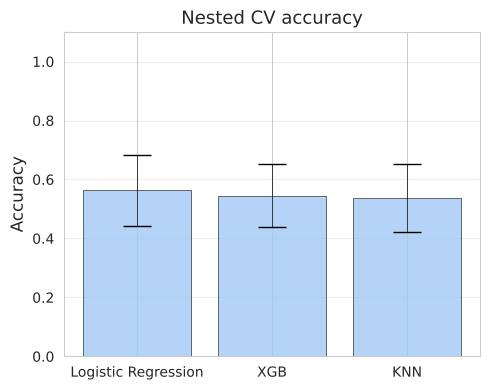

In [17]:
fig, ax = plt.subplots(figsize=(5, 4))

models = [res['model_name'] for res in all_results]
accuracies = [res['accuracy_mean'] for res in all_results]
stds = [res['accuracy_std'] for res in all_results]
bars = ax.bar(models, accuracies, yerr=stds, capsize=10, alpha=0.8, edgecolor='black', linewidth=0.5, error_kw={'linewidth': 0.5})

ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title("Nested CV accuracy", fontsize=13)
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/10_nested_cv_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

### **4.2 AUC Comparison**

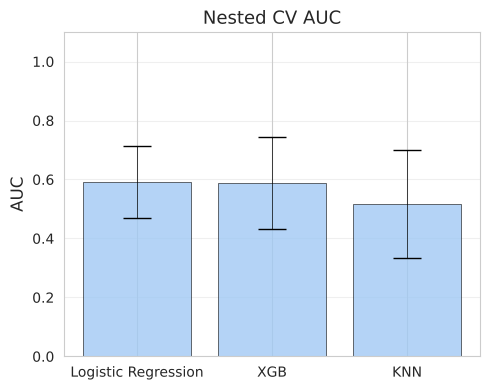

In [18]:
fig, ax = plt.subplots(figsize=(5, 4))

aucs = [res['auc_mean'] for res in all_results]
auc_stds = [res['auc_std'] for res in all_results]

bars = ax.bar(models, aucs, yerr=auc_stds, capsize=10, alpha=0.8, edgecolor='black', linewidth=0.5, error_kw={'linewidth': 0.5})

ax.set_ylabel("AUC", fontsize=12)
ax.set_title("Nested CV AUC", fontsize=13)
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/10_nested_cv_auc.png", dpi=300, bbox_inches='tight')
plt.show()

### **4.3 Fold-by-Fold Accuracy**

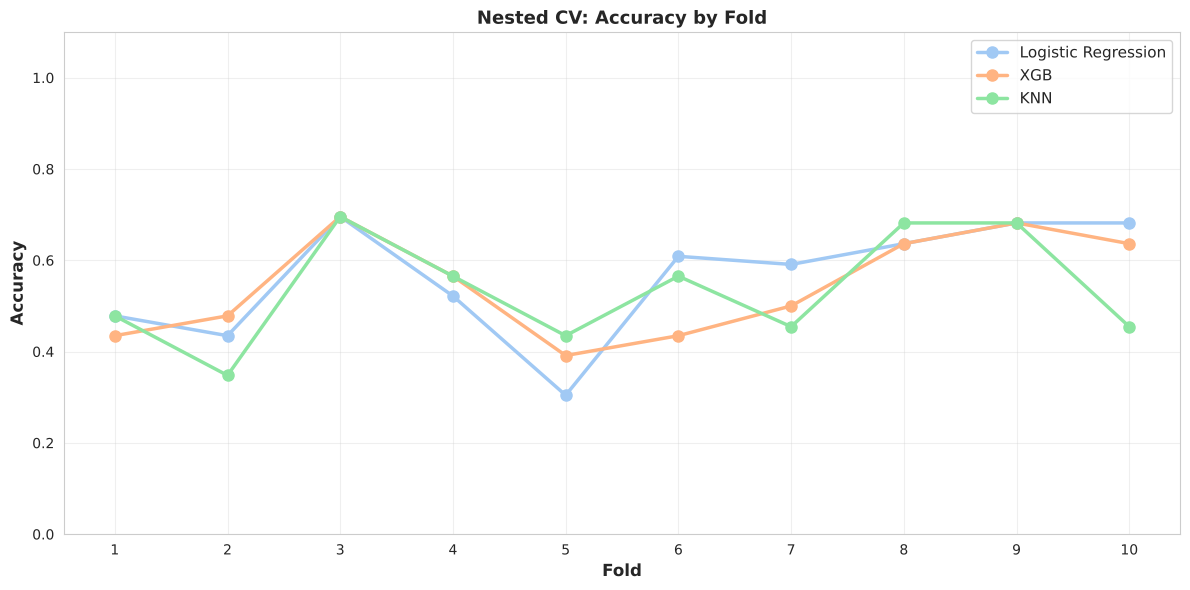

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))

folds = np.arange(1, len(results_lr['accuracies']) + 1)
for res in all_results:
    ax.plot(folds, res['accuracies'], 'o-', linewidth=2.5, markersize=8, label=res['model_name'])

ax.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Nested CV: Accuracy by Fold', fontsize=13, fontweight='bold')
ax.set_xticks(folds)
ax.set_ylim([0, 1.1])
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/10_nested_cv_folds.png", dpi=300, bbox_inches='tight')
plt.show()

### **4.4 Mean ROC Curve**

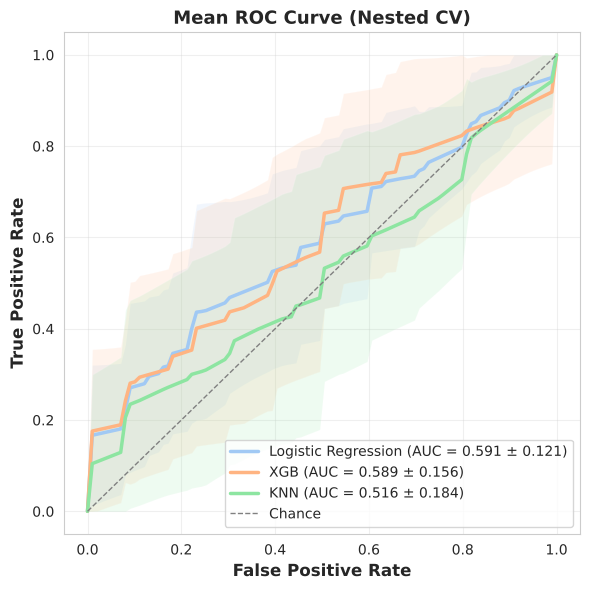

In [20]:
fig, ax = plt.subplots(figsize=(6, 6))

for res in all_results:
    ax.plot(res['mean_fpr'], res['mean_tpr'], linewidth=2.5,
            label=f"{res['model_name']} (AUC = {res['auc_mean']:.3f} \u00b1 {res['auc_std']:.3f})")
    tpr_upper = np.minimum(res['mean_tpr'] + res['std_tpr'], 1)
    tpr_lower = np.maximum(res['mean_tpr'] - res['std_tpr'], 0)
    ax.fill_between(res['mean_fpr'], tpr_lower, tpr_upper, alpha=0.15)

ax.plot([0, 1], [0, 1], linestyle='--', color='grey', linewidth=1, label='Chance')
ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax.set_title('Mean ROC Curve (Nested CV)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/10_nested_cv_roc.png", dpi=300, bbox_inches='tight')
plt.show()

## **5. Conclusions**

In [21]:
# Rank models by accuracy
ranked = sorted(all_results, key=lambda x: x['accuracy_mean'], reverse=True)

print('\nModel Rankings by Accuracy:')
for i, res in enumerate(ranked, 1):
    print(f"{i}. {res['model_name']}: {res['accuracy_mean']:.3f} ± {res['accuracy_std']:.3f}")


Model Rankings by Accuracy:
1. Logistic Regression: 0.563 ± 0.121
2. XGB: 0.545 ± 0.106
3. KNN: 0.536 ± 0.115
